# Final diagnostic 04 — Is the original shared head the bottleneck?

**30 checkpoints**, paired across 5 seeds × 2 curricula × 3 stages. Frozen original encoder and query scorer; each replacement head is trained on the **exact original 8 scalars** using all original train questions.

Controls (40 epochs, same fixed minibatch order, no dev tuning):

1. Original pretrained head (no additional training).
2. Shared original-sized 8→32→2 head (no explicit task ID).
3. Task-aware shared head (8 features + four-hot task ID →32→2).
4. Task-aware wider shared head (8+4→94→2, ~1412 parameters).
5. Four independent task-routed heads (each 8→32→2, ~1416 total parameters).

**Important:** roughly matched parameter counts do not match routing, gradients or functional capacity. This is diagnostic; an improvement alone does not causally prove shared-head gradient interference. We also evaluate the Conjunction Color-present / Shape-missing negative subgroup separately. The same dev split has been inspected before: exploratory only.

In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path().cwd().resolve().parent.parent
if str(PROJECT_ROOT) not in sys.path: sys.path.insert(0, str(PROJECT_ROOT))
import pandas as pd
import numpy as np
import torch
from src.medium_visual_world.diagnostic_followup import (
    load_jsonl, count_free, locate_checkpoint, load_frozen_model,
    run_swaps, extract_object_crops, shape_object_probes,
    scene_shape_head_probe, make_swap
)
from src.medium_visual_world.final_diagnostic_followup import (
    SCHEDULES, SEEDS, STEPS, experiment_grid, experiment_tag,
    validate_manifest, validate_frozen_datasets, verified_sha,
    ensure_run_file, atomic_csv, paired_checkpoint_differences,
    swap_metrics, mean_ci, task_head_competition_controlled
)
from src.medium_visual_world.learning import MediumDataset, AttributeBindingViT, set_seed
OUTPUT = PROJECT_ROOT / "outputs/medium_world/experiments/diagnostic_followup/final_five_seeds"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MANIFEST = validate_manifest(PROJECT_ROOT)   # require the original 30 checkpoints and correct hashes
HASHES = validate_frozen_datasets(PROJECT_ROOT)
print("Validated 30 checkpoints, frozen data hashes, device:", DEVICE)

Validated 30 checkpoints, frozen data hashes, device: cuda


In [2]:
train_ds = MediumDataset(PROJECT_ROOT / "outputs/medium_world/dataset/train.jsonl")
dev_ds = MediumDataset(PROJECT_ROOT / "outputs/medium_world/dataset/id_dev.jsonl")
folder=OUTPUT/"head_competition"
folder.mkdir(parents=True,exist_ok=True)
HEAD_EPOCHS=40
expected_ids=[str(r["id"]) for r in dev_ds.rows]
records=[];per_examples=[]
for schedule,seed,step in experiment_grid():
    tag=experiment_tag(schedule,seed,step)
    checkpoint=locate_checkpoint(PROJECT_ROOT,schedule,seed,step,MANIFEST)
    sha=verified_sha(PROJECT_ROOT,schedule,seed,step,MANIFEST)
    target=folder/f"head_metrics_{tag}.csv"
    pred_path=folder/f"head_predictions_{tag}.csv"
    key={"schedule":schedule,"seed":seed,"step":step,"checkpoint_sha256":sha}
    cached=ensure_run_file(target,("readout","task","accuracy","params"),key,n=25)
    if cached is None:
        model,_=load_frozen_model(checkpoint,DEVICE)
        summary,detail=task_head_competition_controlled(model,train_ds,dev_ds,DEVICE,seed=seed,epochs=HEAD_EPOCHS)
        if list(detail.example_id.astype(str))!=expected_ids:
            raise AssertionError("Per-question head predictions misaligned")
        for k,v in key.items():summary[k]=v;detail[k]=v
        atomic_csv(summary,target);atomic_csv(detail,pred_path)
        del model
        print("COMPUTED",tag)
    else:
        summary=cached
        if not pred_path.is_file():raise FileNotFoundError(f"Missing predictions {pred_path}")
        detail=pd.read_csv(pred_path)
        if (list(detail.example_id.astype(str))!=expected_ids or
                not detail.checkpoint_sha256.eq(sha).all()):
            raise AssertionError(f"Stale/misaligned predictions {pred_path}")
        print("VERIFIED",tag)
    records.append(summary)
    per_examples.append(detail)
result=pd.concat(records,ignore_index=True)
if len(result)!=30*25:
    raise AssertionError("Missing head results")
atomic_csv(result,folder/"head_metrics_all_30_checkpoints.csv")

# One row per seed/schedule/step/task/readout, **no pseudo-replication by examples**.
contrasts=[]
for (task,readout),sub in result.groupby(["task","readout"]):
    c=paired_checkpoint_differences(sub,["accuracy","balanced_accuracy","tpr","tnr"])
    c["task"]=task;c["readout"]=readout;contrasts.append(c)
all_contrasts=pd.concat(contrasts,ignore_index=True)
atomic_csv(all_contrasts,folder/"head_five_seed_stage_contrasts.csv")

# Paired comparisons at each step, WITHIN the same seed and frozen checkpoint.
gaps=[]
for (schedule,step,task),part in result.groupby(["schedule","step","task"]):
    w=part.pivot(index="seed",columns="readout",values="accuracy")
    for a,b in (("task_aware_32","shared_unaware_32"),
                ("task_aware_capacity_matched_94","separate_heads_32"),
                ("separate_heads_32","task_aware_32"),
                ("task_aware_capacity_matched_94","original_pretrained_head")):
        gaps.append(dict(schedule=schedule,step=step,task=task,comparison=f"{a} minus {b}",
                         **mean_ci(w[a]-w[b])))
gaps=pd.DataFrame(gaps)
atomic_csv(gaps,folder/"paired_head_design_comparisons.csv")
display(result.groupby(["step","task","readout"]).accuracy.mean().unstack().round(3))
display(gaps[gaps.task.isin(("shape","pair","conjunction_color_present_shape_missing"))].round(3))

COMPUTED mixed_seed42_step5400
COMPUTED mixed_seed42_step7200
COMPUTED mixed_seed42_step9000
COMPUTED mixed_seed43_step5400
COMPUTED mixed_seed43_step7200
COMPUTED mixed_seed43_step9000
COMPUTED mixed_seed44_step5400
COMPUTED mixed_seed44_step7200
COMPUTED mixed_seed44_step9000
COMPUTED mixed_seed45_step5400
COMPUTED mixed_seed45_step7200
COMPUTED mixed_seed45_step9000
COMPUTED mixed_seed46_step5400
COMPUTED mixed_seed46_step7200
COMPUTED mixed_seed46_step9000
COMPUTED prereq_mixed_pair_focus_seed42_step5400
COMPUTED prereq_mixed_pair_focus_seed42_step7200
COMPUTED prereq_mixed_pair_focus_seed42_step9000
COMPUTED prereq_mixed_pair_focus_seed43_step5400
COMPUTED prereq_mixed_pair_focus_seed43_step7200
COMPUTED prereq_mixed_pair_focus_seed43_step9000
COMPUTED prereq_mixed_pair_focus_seed44_step5400
COMPUTED prereq_mixed_pair_focus_seed44_step7200
COMPUTED prereq_mixed_pair_focus_seed44_step9000
COMPUTED prereq_mixed_pair_focus_seed45_step5400
COMPUTED prereq_mixed_pair_focus_seed45_step7

readout                                       original_pretrained_head  \
step task                                                                
5400 color                                                       0.988   
     conjunction                                                 0.802   
     conjunction_color_present_shape_missing                     0.212   
     pair                                                        0.540   
     shape                                                       0.641   
7200 color                                                       0.968   
     conjunction                                                 0.750   
     conjunction_color_present_shape_missing                     0.402   
     pair                                                        0.641   
     shape                                                       0.611   
9000 color                                                       0.993   
     conjunction                                                 0.802   
     conjunction_color_present_shape_missing                     0.250   
     pair                                                        0.625   
     shape                                                       0.673   

readout                                       separate_heads_32  \
step task                                                         
5400 color                                                0.991   
     conjunction                                          0.809   
     conjunction_color_present_shape_missing              0.263   
     pair                                                 0.600   
     shape                                                0.654   
7200 color                                                0.986   
     conjunction                                          0.800   
     conjunction_color_present_shape_missing              0.279   
     pair                                                 0.661   
     shape                                                0.648   
9000 color                                                0.996   
     conjunction                                          0.805   
     conjunction_color_present_shape_missing              0.342   
     pair                                                 0.658   
     shape                                                0.679   

readout                                       shared_unaware_32  \
step task                                                         
5400 color                                                0.989   
     conjunction                                          0.796   
     conjunction_color_present_shape_missing              0.258   
     pair                                                 0.575   
     shape                                                0.650   
7200 color                                                0.982   
     conjunction                                          0.780   
     conjunction_color_present_shape_missing              0.369   
     pair                                                 0.652   
     shape                                                0.643   
9000 color                                                0.994   
     conjunction                                          0.806   
     conjunction_color_present_shape_missing              0.335   
     pair                                                 0.652   
     shape                                                0.677   

readout                                       task_aware_32  \
step task                                                     
5400 color                                            0.990   
     conjunction                                      0.805   
     conjunction_color_present_shape_missing          0.262   
     pair                                             0.587   
     shape                                            0.652   
7200 color          

,schedule,step,task,comparison,n_seeds,mean,sd,ci95_low,ci95_high,positive_seeds
8,mixed,5400,conjunction_color_present_shape_missing,task_aware_32 minus shared_unaware_32,5,-0.012,0.011,-0.025,0.002,0
9,mixed,5400,conjunction_color_present_shape_missing,task_aware_capacity_matched_94 minus separate_...,5,0.004,0.050,-0.058,0.066,3
10,mixed,5400,conjunction_color_present_shape_missing,separate_heads_32 minus task_aware_32,5,0.004,0.044,-0.051,0.058,2
11,mixed,5400,conjunction_color_present_shape_missing,task_aware_capacity_matched_94 minus original_...,5,0.050,0.067,-0.034,0.134,3
12,mixed,5400,pair,task_aware_32 minus shared_unaware_32,5,0.008,0.008,-0.002,0.018,4
...,...,...,...,...,...,...,...,...,...,...
115,prereq_mixed_pair_focus,9000,pair,task_aware_capacity_matched_94 minus original_...,5,0.024,0.019,0.000,0.048,5
116,prereq_mixed_pair_focus,9000,shape,task_aware_32 minus shared_unaware_32,5,-0.003,0.014,-0.021,0.014,3
117,prereq_mixed_pair_focus,9000,shape,task_aware_capacity_matched_94 minus separate_...,5,-0.002,0.008,-0.012,0.008,1
118,prereq_mixed_pair_focus,9000,shape,separate_heads_32 minus task_aware_32,5,0.007,0.003,0.003,0.011,5


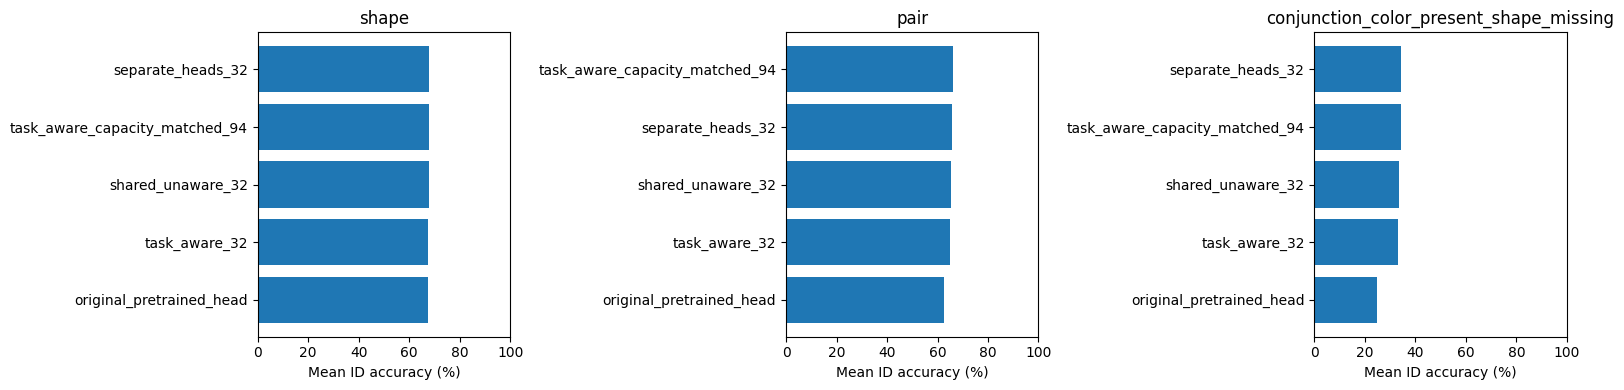

Parameters are frozen through original eight features; only diagnostic heads were trained.


In [3]:
import matplotlib.pyplot as plt
plot=result[(result.task.isin(("shape","pair","conjunction_color_present_shape_missing"))) & (result.step==9000)]
fig,axes = plt.subplots(1,3,figsize=(16,4))
for ax,(task,g) in zip(axes,plot.groupby("task",sort=False)):
    agg=g.groupby("readout").accuracy.mean().sort_values(ascending=False)
    ax.barh(list(agg.index),100*agg.values)
    ax.invert_yaxis();ax.set(xlim=(0,100),xlabel="Mean ID accuracy (%)",title=task)
fig.tight_layout();fig.savefig(folder/"task_head_final_accuracy.png",dpi=180);plt.show()
print("Parameters are frozen through original eight features; only diagnostic heads were trained.")

## Interpretation guardrails

The original model's MLP has implicit operator information in joint-query scalars; it receives no one-hot task ID. Compare task-aware shared and separate heads for a *better controlled* but still imperfect head comparison. Relearned heads have 40 extra epochs of supervised training, while the original head does not. Avoid attributing any gains specifically to architectural design without later ablations. If missing-Shape Conjunction negative accuracy remains near 20–30%, total Conjunction accuracy around 80% is not evidence of logical AND.